# Istanbul Traffic Analytics: Keşifsel Veri Analizi

**Veri:** İBB Saatlik Trafik Yoğunluk Veri Seti, Ekim 2024
**Girdi:** ETL hattının ürettiği `traffic_clean_202410.parquet`

Bu notebook dört soruya yanıt arar:

1. Veri ne kadar eksiksiz ve eksikler rastgele mi?
2. Hız ve araç sayısı nasıl dağılıyor?
3. Trafik gün ve hafta içinde nasıl değişiyor?
4. Araç sayısı arttıkça hız gerçekten düşüyor mu ve tıkanıklık şehirde nerede yoğunlaşıyor?

**Yöntem notu:** Aksi belirtilmedikçe kısmi saatler ve hız aykırıları çıkarılır. Şehir geneli hızlar araç ağırlıklı hesaplanır.

## 1. Kurulum

In [1]:
import logging
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
DATA_PATH = ROOT / "data" / "processed" / "traffic_clean_202410.parquet"
SQL_RESULTS = ROOT / "docs" / "analysis-results"
FIGURE_DIR = ROOT / "docs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
SECONDARY = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
LIGHT_BLUE = "#b7d3f6"

SEQUENTIAL = LinearSegmentedColormap.from_list(
    "traffic_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING = LinearSegmentedColormap.from_list(
    "traffic_diverging", ["#8f2020", "#e34948", "#f0efec", "#3987e5", "#104281"]
)

mpl.rcParams.update({
    "figure.dpi": 100,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": SECONDARY,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.7,
    "xtick.color": SECONDARY,
    "ytick.color": SECONDARY,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def add_title(ax, title, subtitle):
    ax.set_title(title, loc="left", fontsize=13.5, fontweight="semibold", color=INK, pad=28)
    ax.text(0, 1.025, subtitle, transform=ax.transAxes, color=SECONDARY, fontsize=9.5, va="bottom")


def save(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


def weighted_speed(frame, by):
    totals = frame.groupby(by, observed=True)[["speed_volume", "vehicle_count"]].sum()
    return totals["speed_volume"] / totals["vehicle_count"]

In [2]:
df = pd.read_parquet(DATA_PATH)
df["hour"] = df["observed_at"].dt.hour
df["date"] = df["observed_at"].dt.normalize()
df["speed_volume"] = df["avg_speed_kmh"].astype("int64") * df["vehicle_count"]

eligible = df[df["is_analysis_eligible"]].copy()
reliable = eligible[~eligible["is_low_sample"]].copy()

pd.Series({
    "Satır": f"{len(df):,}",
    "Analize uygun satır": f"{len(eligible):,}",
    "Güvenilir örneklemli satır": f"{len(reliable):,}",
    "Konum hücresi": f"{df['geohash'].nunique():,}",
    "Saat": f"{df['observed_at'].nunique():,}",
    "İlk saat": str(df["observed_at"].min()),
    "Son saat": str(df["observed_at"].max()),
}, name="Değer").to_frame()

,Değer
Satır,"1,769,643"
Analize uygun satır,"1,760,101"
Güvenilir örneklemli satır,"1,647,409"
Konum hücresi,"2,458"
Saat,744
İlk saat,2024-10-01 00:00:00
Son saat,2024-10-31 23:00:00


## 2. Veri kapsamı ve eksikler

Her saatin araç sayısını, haftanın aynı gününün aynı saatindeki medyan seviyeyle karşılaştırıyoruz.

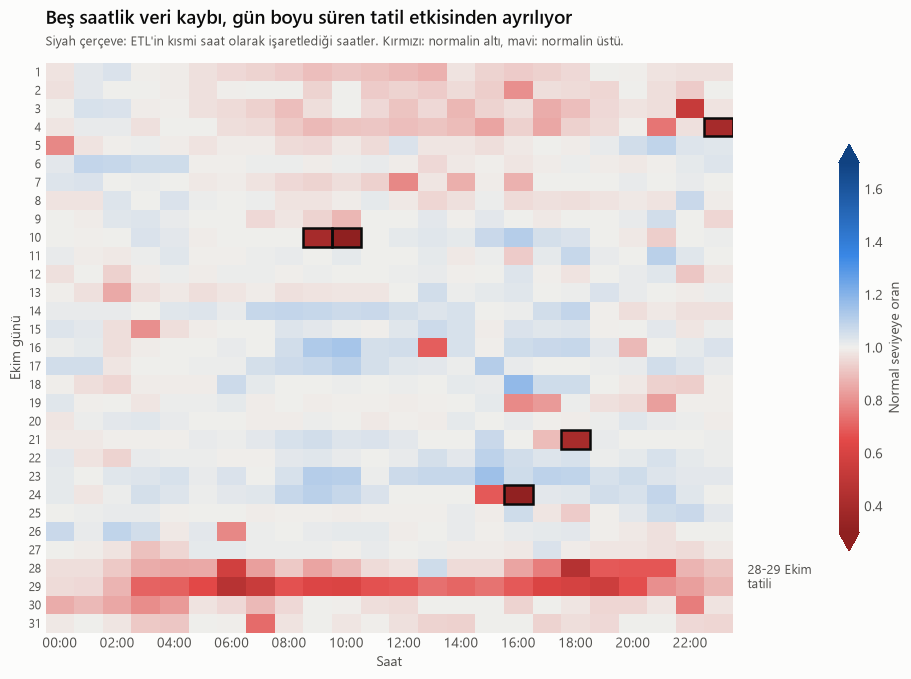

In [3]:
hourly = (
    df.groupby(["date", "hour"])
    .agg(
        vehicles=("vehicle_count", "sum"),
        holiday=("is_public_holiday", "first"),
        weekend=("is_weekend", "first"),
        partial=("is_partial_hour", "first"),
    )
    .reset_index()
)
hourly["day_of_week"] = hourly["date"].dt.dayofweek
normal = hourly[~hourly["holiday"]].groupby(["day_of_week", "hour"])["vehicles"].median().rename("normal")
hourly = hourly.join(normal, on=["day_of_week", "hour"])
hourly["ratio"] = hourly["vehicles"] / hourly["normal"]
ratio_grid = hourly.pivot(index="date", columns="hour", values="ratio")

fig, ax = plt.subplots(figsize=(10.5, 7.4))
image = ax.imshow(
    ratio_grid,
    aspect="auto",
    cmap=DIVERGING,
    norm=TwoSlopeNorm(vmin=0.3, vcenter=1, vmax=1.7),
    interpolation="nearest",
)
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_xticks(range(0, 24, 2), [f"{hour:02d}:00" for hour in range(0, 24, 2)])
ax.set_yticks(range(len(ratio_grid)), [str(day.day) for day in ratio_grid.index], fontsize=8.5)
ax.set_xlabel("Saat")
ax.set_ylabel("Ekim günü")

dates = list(ratio_grid.index)
for row in hourly[hourly["partial"]].itertuples():
    ax.add_patch(Rectangle((row.hour - 0.5, dates.index(row.date) - 0.5), 1, 1, fill=False, edgecolor=INK, linewidth=1.8))

ax.annotate(
    "28-29 Ekim\ntatili", xy=(23.5, 27.5), xytext=(24.0, 27.5), annotation_clip=False,
    va="center", fontsize=9, color=SECONDARY,
)
colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.13, extend="both")
colorbar.set_label("Normal seviyeye oran")
colorbar.outline.set_visible(False)
colorbar.ax.tick_params(size=0)
add_title(
    ax,
    "Beş saatlik veri kaybı, gün boyu süren tatil etkisinden ayrılıyor",
    "Siyah çerçeve: ETL'in kısmi saat olarak işaretlediği saatler. Kırmızı: normalin altı, mavi: normalin üstü.",
)
save(fig, "fig01_outages")

**Yorum**

- Veri kayıpları tek saatlik, keskin kırmızı noktalar olarak görünür. 29 Ekim'deki düşüş ise bütün güne yayılır ve gerçek bir tatil etkisidir.
- ETL'in işaretlediği beş saat, ısı haritasında gözle de ayrışıyor. Bu, kısmi saat kuralının mantıklı çalıştığını destekler.
- 3 Ekim 22:00, 16 Ekim 13:00 ve 24 Ekim 15:00 gibi saatlerde daha hafif düşüşler de vardır. %50 eşiği bunları bilerek işaretlemez.

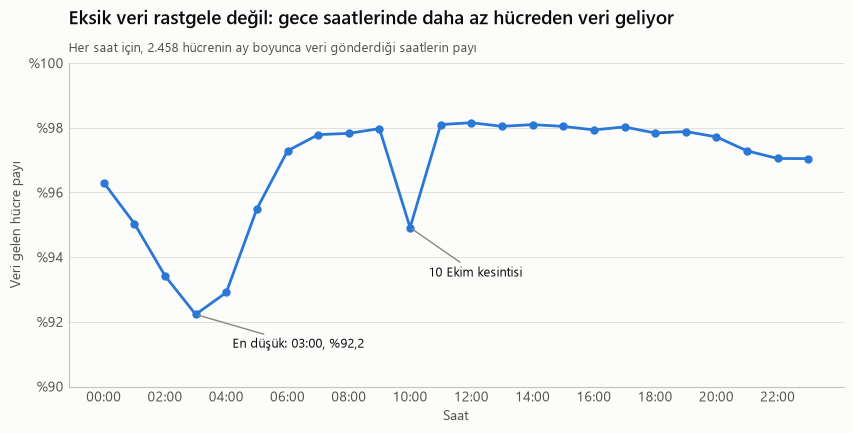

,Değer
%99 ve üzeri kapsama sahip hücre,81.9%
%50 altı kapsamaya sahip hücre,54
Bu hücrelerin satır payı,0.38%
Kapsama ve araç sayısı sıra korelasyonu,0.752


In [4]:
cell_count = df["geohash"].nunique()
coverage_by_hour = df.groupby("hour").size() / (cell_count * df["date"].nunique()) * 100

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(coverage_by_hour.index, coverage_by_hour.values, color=BLUE, marker="o", markersize=5)
ax.set_ylim(90, 100)
ax.set_xticks(range(0, 24, 2), [f"{hour:02d}:00" for hour in range(0, 24, 2)])
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"%{value:.0f}"))
ax.set_xlabel("Saat")
ax.set_ylabel("Veri gelen hücre payı")
ax.grid(axis="x", visible=False)
low_hour = coverage_by_hour.idxmin()
ax.annotate(
    f"En düşük: {low_hour:02d}:00, %{coverage_by_hour[low_hour]:.1f}".replace(".", ","),
    xy=(low_hour, coverage_by_hour[low_hour]), xytext=(low_hour + 1.2, 91.2),
    color=INK, fontsize=9.5, arrowprops={"arrowstyle": "-", "color": MUTED},
)
ax.annotate(
    "10 Ekim kesintisi", xy=(10, coverage_by_hour[10]), xytext=(10.6, 93.4),
    color=INK, fontsize=9.5, arrowprops={"arrowstyle": "-", "color": MUTED},
)
add_title(ax, "Eksik veri rastgele değil: gece saatlerinde daha az hücreden veri geliyor", "Her saat için, 2.458 hücrenin ay boyunca veri gönderdiği saatlerin payı")
save(fig, "fig02_coverage")

cell_coverage = df.groupby("geohash").agg(rows=("geohash", "size"), median_vehicles=("vehicle_count", "median"))
cell_coverage["coverage"] = cell_coverage["rows"] / df["observed_at"].nunique()
coverage_rank_corr = cell_coverage["coverage"].rank().corr(cell_coverage["median_vehicles"].rank())
sparse_cells = cell_coverage[cell_coverage["coverage"] < 0.5]

pd.Series({
    "%99 ve üzeri kapsama sahip hücre": f"{(cell_coverage['coverage'] >= 0.99).mean():.1%}",
    "%50 altı kapsamaya sahip hücre": len(sparse_cells),
    "Bu hücrelerin satır payı": f"{sparse_cells['rows'].sum() / len(df):.2%}",
    "Kapsama ve araç sayısı sıra korelasyonu": round(coverage_rank_corr, 3),
}, name="Değer").to_frame()

**Yorum**

- Veri gelen hücre payı gündüz yaklaşık %98, 03:00'te %92,2'dir. Eksik satırlar büyük olasılıkla o saatte hücreden araç geçmediğini gösterir.
- Hücrelerin %81,9'u ayın en az %99'unda veri üretir. Kapsama ile araç sayısı arasındaki sıra korelasyonu 0,752'dir, yani seyrek hücreler sakin hücrelerdir.
- Kapsaması %50'nin altındaki 54 hücre, satırların yalnızca %0,38'ini oluşturur. **Eksik saatler sıfır araç olarak doldurulmamalıdır**, çünkü gerçek değer bilinmiyor.

## 3. Hız ve araç sayısı dağılımları

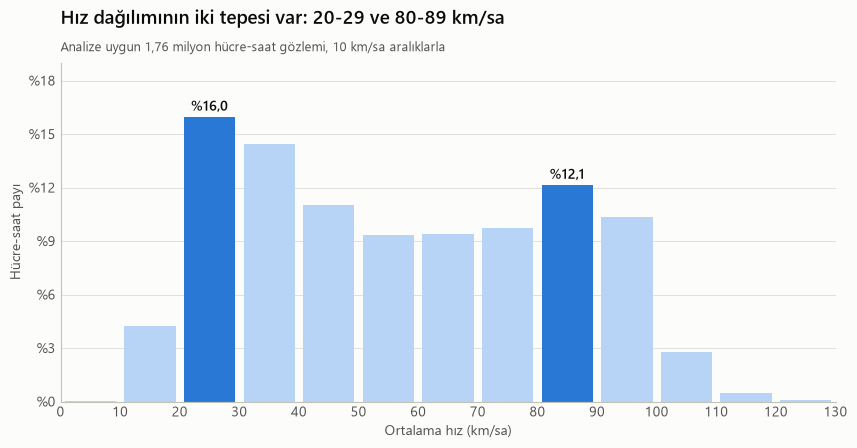

In [5]:
bins = np.arange(0, 131, 10)
counts, _ = np.histogram(eligible["avg_speed_kmh"], bins=bins)
shares = counts / counts.sum() * 100
peak_bins = {20, 80}

fig, ax = plt.subplots(figsize=(10, 4.4))
colors = [BLUE if left in peak_bins else LIGHT_BLUE for left in bins[:-1]]
ax.bar(bins[:-1] + 5, shares, width=8.6, color=colors)
for left, share in zip(bins[:-1], shares):
    if left in peak_bins:
        ax.text(left + 5, share + 0.35, f"%{share:.1f}".replace(".", ","), ha="center", color=INK, fontsize=10, fontweight="semibold")
ax.set_xticks(bins)
ax.set_xlim(0, 130)
ax.set_ylim(0, 19)
ax.set_yticks(range(0, 19, 3))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"%{value:.0f}"))
ax.set_xlabel("Ortalama hız (km/sa)")
ax.set_ylabel("Hücre-saat payı")
ax.grid(axis="x", visible=False)
add_title(ax, "Hız dağılımının iki tepesi var: 20-29 ve 80-89 km/sa", "Analize uygun 1,76 milyon hücre-saat gözlemi, 10 km/sa aralıklarla")
save(fig, "fig03_speed_distribution")

**Yorum**

- Dağılım tek tepeli değildir. 20-29 km/sa (%16,0) ve 80-89 km/sa (%12,1) aralıklarında iki yoğunlaşma vardır, arada 50-69 km/sa bandı daha seyrektir.
- İki tepe, hücrelerin farklı yol tiplerini temsil ettiğine işaret eder. Bu nedenle **tek bir şehir ortalaması, tipik bir hücreyi temsil etmez.**

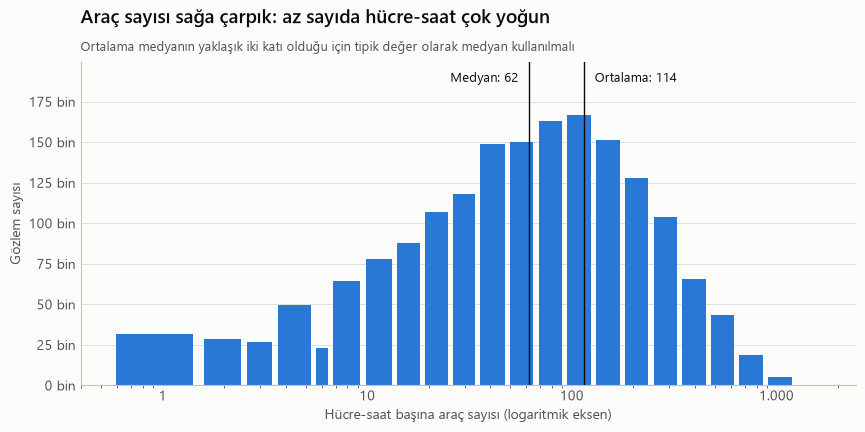

In [6]:
vehicle_bins = np.unique(np.ceil(np.logspace(0, np.log10(eligible["vehicle_count"].max() + 1), 24))) - 0.5
median_vehicles = eligible["vehicle_count"].median()
mean_vehicles = eligible["vehicle_count"].mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(eligible["vehicle_count"], bins=vehicle_bins, color=BLUE, rwidth=0.82)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", ".")))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1000:.0f} bin"))
ax.set_xlabel("Hücre-saat başına araç sayısı (logaritmik eksen)")
ax.set_ylabel("Gözlem sayısı")
ax.grid(axis="x", visible=False)
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.14)
for value, label, offset in [(median_vehicles, f"Medyan: {median_vehicles:.0f}", -8), (mean_vehicles, f"Ortalama: {mean_vehicles:.0f}", 8)]:
    ax.axvline(value, color=INK, linewidth=1)
    ax.annotate(label, xy=(value, top * 1.07), xytext=(offset, 0), textcoords="offset points", ha="right" if offset < 0 else "left", fontsize=9.5)
add_title(ax, "Araç sayısı sağa çarpık: az sayıda hücre-saat çok yoğun", "Ortalama medyanın yaklaşık iki katı olduğu için tipik değer olarak medyan kullanılmalı")
save(fig, "fig04_vehicle_distribution")

**Yorum**

- Medyan 62 araç, ortalama 114 araçtır ve çarpıklık 2,55'tir. Yoğun saatler ortalamayı yukarı çeker.
- Logaritmik eksende dağılım çok daha dengelidir. Dashboard'daki araç sayısı renk ölçekleri bu yüzden doğrusal değil, logaritmik veya yüzdelik dilimli olmalıdır.

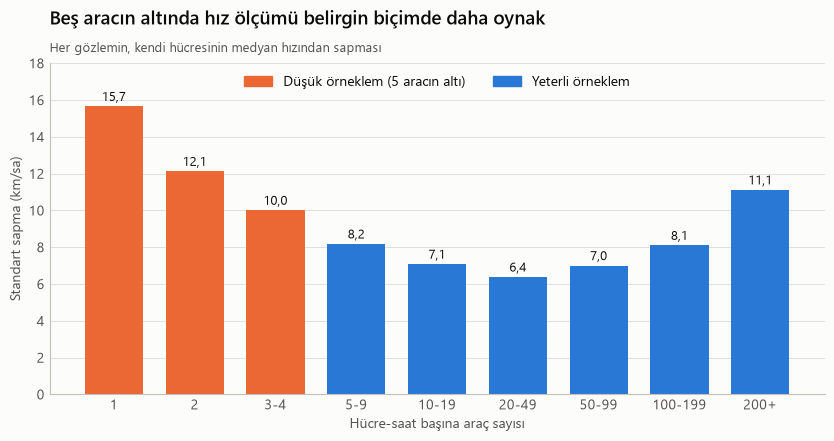

In [7]:
labels = ["1", "2", "3-4", "5-9", "10-19", "20-49", "50-99", "100-199", "200+"]
sample = eligible[["geohash", "avg_speed_kmh", "vehicle_count"]].copy()
sample["bucket"] = pd.cut(sample["vehicle_count"], [0, 1, 2, 4, 9, 19, 49, 99, 199, np.inf], labels=labels)
sample["deviation"] = sample["avg_speed_kmh"] - sample.groupby("geohash")["avg_speed_kmh"].transform("median")
noise = sample.groupby("bucket", observed=True)["deviation"].std()

fig, ax = plt.subplots(figsize=(10, 4.3))
colors = [ORANGE if label in labels[:3] else BLUE for label in noise.index]
ax.bar(noise.index.astype(str), noise.values, color=colors, width=0.72)
for index, value in enumerate(noise.values):
    ax.text(index, value + 0.3, f"{value:.1f}".replace(".", ","), ha="center", fontsize=9.5, color=INK)
ax.set_ylim(0, 18)
ax.set_xlabel("Hücre-saat başına araç sayısı")
ax.set_ylabel("Standart sapma (km/sa)")
ax.grid(axis="x", visible=False)
ax.legend(
    handles=[Patch(color=ORANGE, label="Düşük örneklem (5 aracın altı)"), Patch(color=BLUE, label="Yeterli örneklem")],
    loc="upper center", ncols=2,
)
add_title(ax, "Beş aracın altında hız ölçümü belirgin biçimde daha oynak", "Her gözlemin, kendi hücresinin medyan hızından sapması")
save(fig, "fig05_sample_noise")

**Yorum**

- Tek araçlı gözlemlerde standart sapma 15,7 km/sa'dir. 5-9 araçta 8,2 km/sa'e, 20-49 araçta 6,4 km/sa'e iner. **ETL'deki 5 araç eşiği veriyle destekleniyor.**
- 200 ve üzeri araçta sapma yeniden 11,1 km/sa'e çıkar. Bunun nedeni ölçüm gürültüsü değil, yoğun hücrelerde hızın gün içinde gerçekten çok değişmesidir.

## 4. Zaman örüntüleri

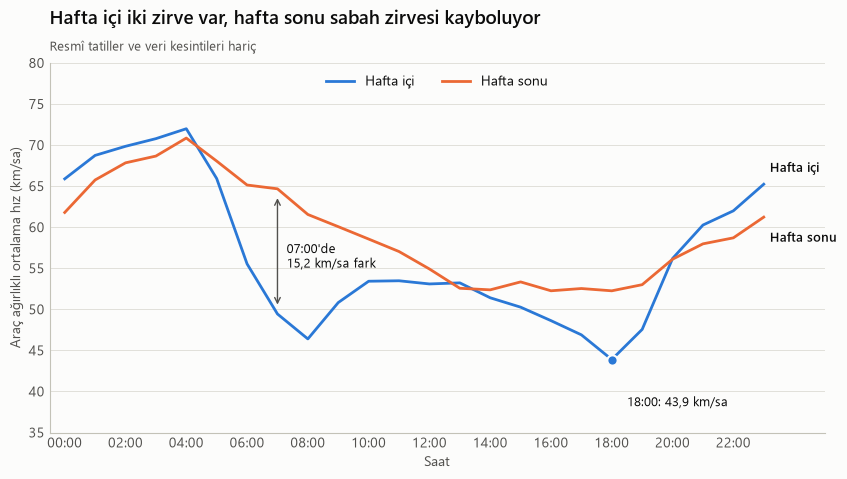

In [8]:
normal_days = eligible[~eligible["is_public_holiday"]]
weekday_speed = weighted_speed(normal_days[~normal_days["is_weekend"]], "hour")
weekend_speed = weighted_speed(normal_days[normal_days["is_weekend"]], "hour")

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(weekday_speed.index, weekday_speed.values, color=BLUE, label="Hafta içi")
ax.plot(weekend_speed.index, weekend_speed.values, color=ORANGE, label="Hafta sonu")
ax.set_xticks(range(0, 24, 2), [f"{hour:02d}:00" for hour in range(0, 24, 2)])
ax.set_ylim(35, 80)
ax.set_xlim(-0.5, 25)
ax.set_xlabel("Saat")
ax.set_ylabel("Araç ağırlıklı ortalama hız (km/sa)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", ncols=2)
ax.text(23.2, weekday_speed[23] + 1.5, "Hafta içi", color=INK, fontsize=9.5, fontweight="semibold")
ax.text(23.2, weekend_speed[23] - 3, "Hafta sonu", color=INK, fontsize=9.5, fontweight="semibold")
ax.scatter([18], [weekday_speed[18]], color=BLUE, s=55, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.annotate(f"18:00: {weekday_speed[18]:.1f} km/sa".replace(".", ","), xy=(18, weekday_speed[18]), xytext=(18.5, 38.2), fontsize=9.5)
ax.annotate(
    "", xy=(7, weekend_speed[7] - 0.8), xytext=(7, weekday_speed[7] + 0.8),
    arrowprops={"arrowstyle": "<->", "color": SECONDARY, "linewidth": 1},
)
ax.text(7.3, 56.4, "07:00'de\n15,2 km/sa fark", fontsize=9.5, ha="left", va="center", color=INK)
add_title(ax, "Hafta içi iki zirve var, hafta sonu sabah zirvesi kayboluyor", "Resmî tatiller ve veri kesintileri hariç")
save(fig, "fig06_hourly_profile")

**Yorum**

- Hafta içi hız 08:00'de 46,4 km/sa, 18:00'de 43,9 km/sa ile iki kez dibe vurur. **Akşam zirvesi sabah zirvesinden daha yavaştır.**
- Hafta sonu sabah zirvesi yoktur. En büyük fark 07:00'de 15,2 km/sa'tir.
- Gece hafta sonları hafta içinden daha yavaştır (00:00'de 4,1 km/sa). Hafta sonu gece trafiğinin daha yoğun olması bu farkı açıklayabilir.

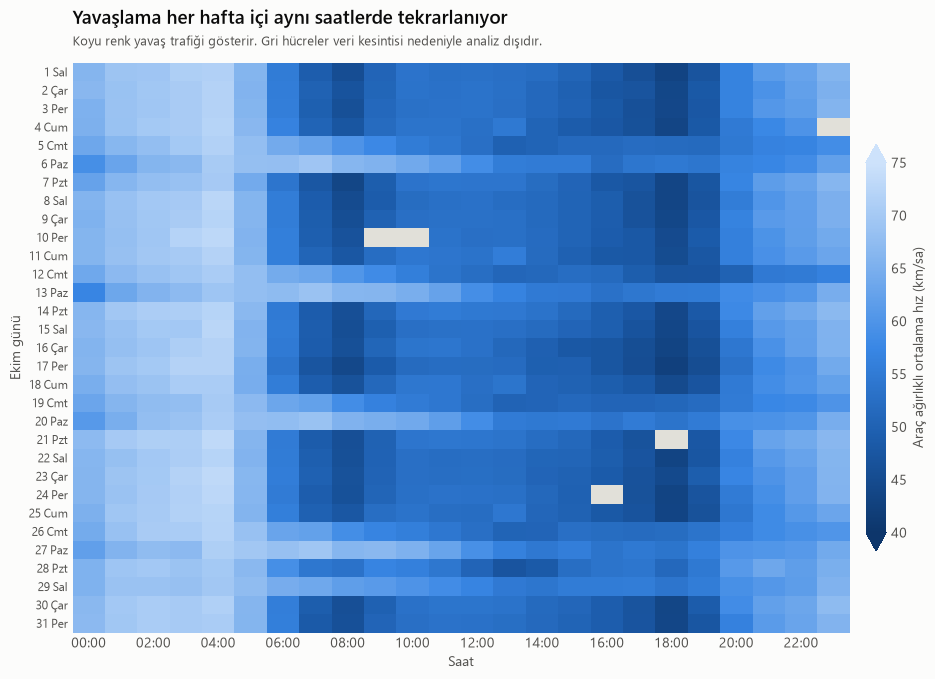

,Hafta içi günler arası standart sapma (km/sa)
hour,
8,1.81
18,0.63


In [9]:
speed_grid = weighted_speed(eligible, ["date", "hour"]).unstack()
day_names = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]

fig, ax = plt.subplots(figsize=(10.5, 7.4))
cmap = SEQUENTIAL.reversed().copy()
cmap.set_bad(GRID)
image = ax.imshow(speed_grid, aspect="auto", cmap=cmap, vmin=40, vmax=75, interpolation="nearest")
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_xticks(range(0, 24, 2), [f"{hour:02d}:00" for hour in range(0, 24, 2)])
ax.set_yticks(range(len(speed_grid)), [f"{day.day} {day_names[day.dayofweek]}" for day in speed_grid.index], fontsize=8.5)
ax.set_xlabel("Saat")
ax.set_ylabel("Ekim günü")
colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02, extend="both")
colorbar.set_label("Araç ağırlıklı ortalama hız (km/sa)")
colorbar.outline.set_visible(False)
colorbar.ax.tick_params(size=0)
add_title(ax, "Yavaşlama her hafta içi aynı saatlerde tekrarlanıyor", "Koyu renk yavaş trafiği gösterir. Gri hücreler veri kesintisi nedeniyle analiz dışıdır.")
save(fig, "fig07_speed_heatmap")

weekday_grid = weighted_speed(
    eligible[(~eligible["is_weekend"]) & (~eligible["is_public_holiday"])], ["date", "hour"]
).unstack()
weekday_grid.std().round(2).rename("Hafta içi günler arası standart sapma (km/sa)").loc[[8, 18]].to_frame()

**Yorum**

- Sabah ve akşam zirveleri her hafta içi aynı saatlerde koyu bantlar oluşturur. Trafik örüntüsü büyük ölçüde **öngörülebilirdir**.
- 18:00 hızının hafta içi günler arasındaki standart sapması yalnızca 0,63 km/sa'tir. 08:00'de bu değer 1,81 km/sa'e çıkar, yani sabah trafiği günden güne daha değişkendir.
- 29 Ekim satırı sabah saatlerinde çevresindeki hafta içi günlerden belirgin biçimde açık renklidir.

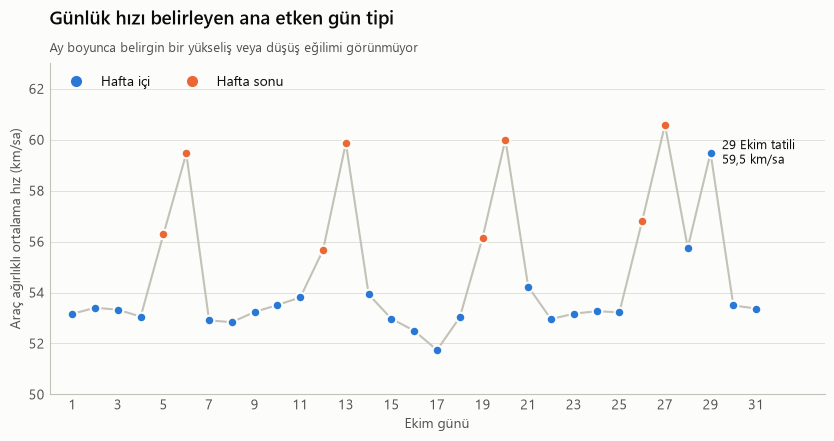

In [10]:
daily = weighted_speed(eligible, "date").rename("speed").to_frame()
daily["weekend"] = daily.index.dayofweek >= 5

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(daily.index, daily["speed"], color=AXIS, linewidth=1.5, zorder=1)
for is_weekend, color in [(False, BLUE), (True, ORANGE)]:
    part = daily[daily["weekend"] == is_weekend]
    ax.scatter(part.index, part["speed"], color=color, s=48, zorder=2, edgecolor=SURFACE, linewidth=1.5)
holiday = pd.Timestamp("2024-10-29")
ax.text(
    pd.Timestamp("2024-10-29 12:00"), daily.loc[holiday, "speed"],
    f"29 Ekim tatili\n{daily.loc[holiday, 'speed']:.1f} km/sa".replace(".", ","),
    fontsize=9.5, va="center",
)
ax.set_xlim(pd.Timestamp("2024-09-30"), pd.Timestamp("2024-11-03"))
ax.set_ylim(50, 63)
ax.set_xticks(daily.index[::2], [str(day.day) for day in daily.index[::2]])
ax.set_xlabel("Ekim günü")
ax.set_ylabel("Araç ağırlıklı ortalama hız (km/sa)")
ax.grid(axis="x", visible=False)
ax.legend(
    handles=[
        Line2D([], [], marker="o", color="none", markerfacecolor=BLUE, markeredgecolor=BLUE, markersize=7, label="Hafta içi"),
        Line2D([], [], marker="o", color="none", markerfacecolor=ORANGE, markeredgecolor=ORANGE, markersize=7, label="Hafta sonu"),
    ],
    loc="upper left", ncols=2,
)
add_title(ax, "Günlük hızı belirleyen ana etken gün tipi", "Ay boyunca belirgin bir yükseliş veya düşüş eğilimi görünmüyor")
save(fig, "fig08_daily_trend")

**Yorum**

- Hafta içi günler dar bir bantta kalırken pazar günleri 59-61 km/sa seviyesine çıkar.
- 29 Ekim tatili salı olmasına rağmen pazar günlerine yakın bir hızla öne çıkar.
- Tek ayda belirgin bir eğilim görünmemesi şaşırtıcı değildir. Mevsimsel yorum için daha fazla ay gerekir.

## 5. Araç sayısı ve hız ilişkisi

SQL analizinde tüm gözlemler üzerinden korelasyon -0,059 çıkmıştı. Bu değer, "kalabalık hızı etkilemiyor" anlamına mı geliyor? Her hücreyi kendi içinde inceleyerek sınıyoruz.

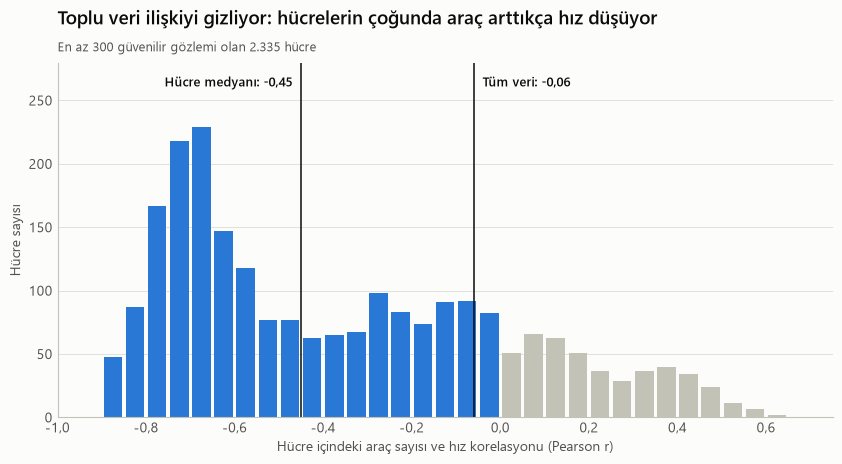

,Medyan r
median_vehicles,
En sakin %25,-0.141
%25-50,-0.422
%50-75,-0.636
En yoğun %25,-0.660


In [11]:
observations = reliable.groupby("geohash")["vehicle_count"].transform("size")
stable = reliable[observations >= 300]

pooled_r = reliable["vehicle_count"].corr(reliable["avg_speed_kmh"])
within_r = (
    stable.groupby("geohash")[["vehicle_count", "avg_speed_kmh"]]
    .corr().iloc[0::2, 1].droplevel(1).rename("r")
)

fig, ax = plt.subplots(figsize=(10, 4.6))
r_bins = np.arange(-1, 1.01, 0.05)
counts, edges = np.histogram(within_r, bins=r_bins)
colors = [BLUE if left < -1e-9 else AXIS for left in edges[:-1]]
ax.bar(edges[:-1] + 0.025, counts, width=0.042, color=colors)
ax.set_xlim(-1, 0.75)
ax.set_ylim(0, counts.max() * 1.22)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.1f}".replace(".", ",")))
ax.set_xlabel("Hücre içindeki araç sayısı ve hız korelasyonu (Pearson r)")
ax.set_ylabel("Hücre sayısı")
ax.grid(axis="x", visible=False)
for value, label, align, offset in [
    (within_r.median(), f"Hücre medyanı: {within_r.median():.2f}", "right", -6),
    (pooled_r, f"Tüm veri: {pooled_r:.2f}", "left", 6),
]:
    ax.axvline(value, color=INK, linewidth=1.1)
    ax.annotate(
        label.replace(".", ","), xy=(value, counts.max() * 1.14), xytext=(offset, 0),
        textcoords="offset points", ha=align, fontsize=9.5, fontweight="semibold",
    )
add_title(ax, "Toplu veri ilişkiyi gizliyor: hücrelerin çoğunda araç arttıkça hız düşüyor", f"En az 300 güvenilir gözlemi olan {len(within_r):,} hücre".replace(",", "."))
save(fig, "fig09_within_cell_correlation")

cell_summary = stable.groupby("geohash").agg(median_vehicles=("vehicle_count", "median"), median_speed=("avg_speed_kmh", "median"))
cell_summary["r"] = within_r
quartile_r = cell_summary.groupby(
    pd.qcut(cell_summary["median_vehicles"], 4, labels=["En sakin %25", "%25-50", "%50-75", "En yoğun %25"]), observed=True
)["r"].median().round(3)
quartile_r.rename("Medyan r").to_frame()

**Yorum**

- Tüm gözlemler birlikte incelendiğinde korelasyon -0,059'dur, fakat hücre içi medyan korelasyon **-0,451**'dir. Hücrelerin %80,6'sında ilişki negatiftir.
- Bu, **Simpson paradoksunun** bir örneğidir. Otoyol hücreleri hem kalabalık hem hızlı, ara sokak hücreleri hem sakin hem yavaş olduğu için hücreler arası fark, hücre içindeki gerçek ilişkiyi gizler.
- İlişki yoğun hücrelerde güçlenir: en sakin çeyrekte medyan r -0,141, en yoğun çeyrekte -0,660'tır.

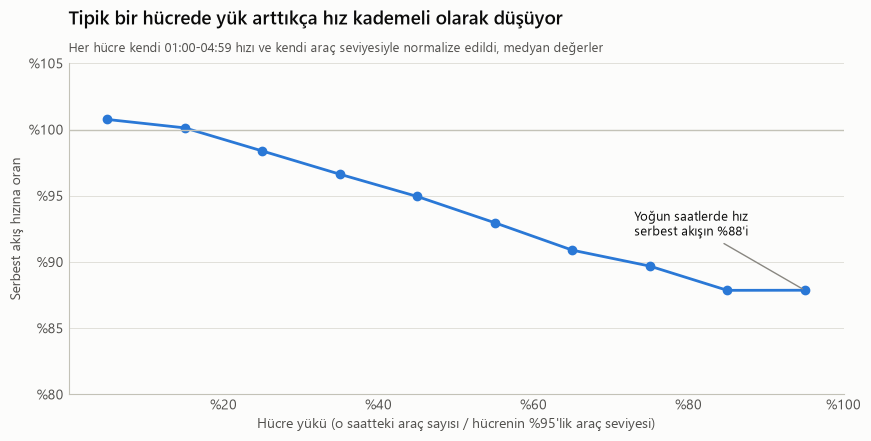

In [12]:
free_flow = weighted_speed(stable[stable["hour"].between(1, 4)], "geohash").rename("free_flow")
capacity = stable.groupby("geohash")["vehicle_count"].quantile(0.95).rename("capacity")
relative = stable.join(free_flow, on="geohash").join(capacity, on="geohash").dropna(subset=["free_flow", "capacity"])
relative["load"] = relative["vehicle_count"] / relative["capacity"]
relative["relative_speed"] = relative["avg_speed_kmh"] / relative["free_flow"]

load_edges = np.arange(0, 1.01, 0.1)
binned = relative[relative["load"] <= 1].groupby(pd.cut(relative["load"], load_edges), observed=True)["relative_speed"].median() * 100
midpoints = load_edges[:-1] + 0.05

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(midpoints * 100, binned.values, color=BLUE, marker="o", markersize=6)
ax.set_xlim(0, 100)
ax.set_xticks(range(20, 101, 20))
ax.set_ylim(80, 105)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"%{value:.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"%{value:.0f}"))
ax.axhline(100, color=AXIS, linewidth=1)
ax.set_xlabel("Hücre yükü (o saatteki araç sayısı / hücrenin %95'lik araç seviyesi)")
ax.set_ylabel("Serbest akış hızına oran")
ax.grid(axis="x", visible=False)
ax.annotate(
    f"Yoğun saatlerde hız\nserbest akışın %{binned.iloc[-1]:.0f}'i".replace(".", ","),
    xy=(midpoints[-1] * 100, binned.iloc[-1]), xytext=(73, 92), fontsize=9.5,
    arrowprops={"arrowstyle": "-", "color": MUTED},
)
add_title(ax, "Tipik bir hücrede yük arttıkça hız kademeli olarak düşüyor", "Her hücre kendi 01:00-04:59 hızı ve kendi araç seviyesiyle normalize edildi, medyan değerler")
save(fig, "fig10_load_speed")

**Yorum**

- Her hücre kendi ölçeğine getirildiğinde ilişki düzenli bir eğri oluşturur. Yük %10'dan %95'e çıkarken medyan hız serbest akışın yaklaşık %100'ünden %88'ine iner.
- Bu **medyan** bir eğridir. Sokak düzeyindeki sıkışmalar, özellikle yoğun hücrelerde bu ortalamanın çok ötesine geçebilir.

## 6. Tıkanıklığın mekânsal dağılımı

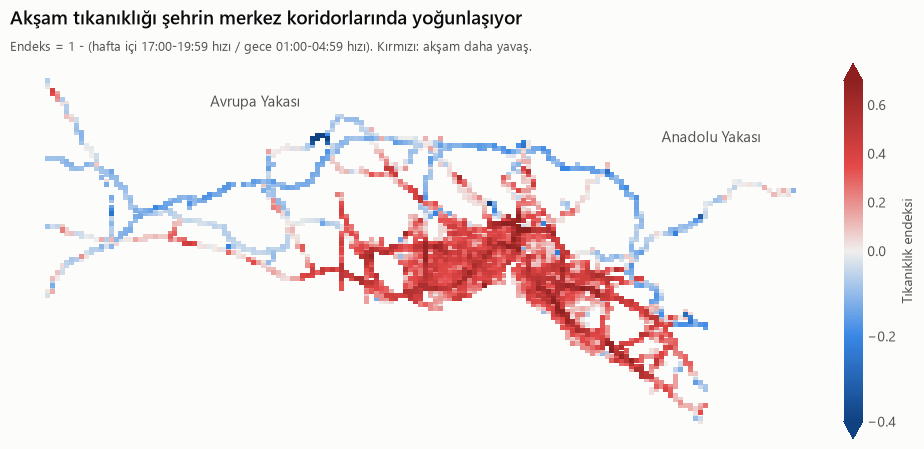

,hucre,medyan_endeks
longitude_band,,
"(27.9, 28.4]",252,-0.060
"(28.4, 28.7]",323,0.020
"(28.7, 28.9]",512,0.280
"(28.9, 29.1]",544,0.294
"(29.1, 29.3]",454,0.244
"(29.3, 29.7]",235,0.068


In [13]:
evening = reliable[(~reliable["is_weekend"]) & (~reliable["is_public_holiday"]) & (reliable["hour"].between(17, 19))]
night = reliable[reliable["hour"].between(1, 4)]
locations = df.drop_duplicates("geohash").set_index("geohash")[["latitude", "longitude"]]

congestion = pd.concat(
    [weighted_speed(night, "geohash").rename("night"), weighted_speed(evening, "geohash").rename("peak")],
    axis=1,
).dropna().join(locations)
congestion["index"] = 1 - congestion["peak"] / congestion["night"]

fig, ax = plt.subplots(figsize=(11, 6.2))
ordered = congestion.sort_values("index", key=lambda values: values.abs())
points = ax.scatter(
    ordered["longitude"], ordered["latitude"], c=ordered["index"], cmap=DIVERGING.reversed(),
    norm=TwoSlopeNorm(vmin=-0.4, vcenter=0, vmax=0.7), s=13, marker="s", linewidths=0,
)
ax.set_aspect(1 / np.cos(np.radians(41)))
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.text(28.33, 41.30, "Avrupa Yakası", fontsize=10.5, color=SECONDARY)
ax.text(29.34, 41.24, "Anadolu Yakası", fontsize=10.5, color=SECONDARY)
colorbar = fig.colorbar(points, ax=ax, fraction=0.022, pad=0.015, extend="both")
colorbar.set_label("Tıkanıklık endeksi")
colorbar.outline.set_visible(False)
colorbar.ax.tick_params(size=0)
add_title(ax, "Akşam tıkanıklığı şehrin merkez koridorlarında yoğunlaşıyor", "Endeks = 1 - (hafta içi 17:00-19:59 hızı / gece 01:00-04:59 hızı). Kırmızı: akşam daha yavaş.")
save(fig, "fig11_congestion_map")

congestion["longitude_band"] = pd.cut(congestion["longitude"], [27.9, 28.4, 28.7, 28.9, 29.1, 29.3, 29.7])
congestion.groupby("longitude_band", observed=True)["index"].agg(hucre="size", medyan_endeks="median").round(3)

**Yorum**

- Boylam 28,7-29,3 arasındaki merkez bantlarda medyan endeks 0,24-0,29'dur. Şehrin doğu ve batı uçlarında endeks sıfıra yakındır.
- 2.320 hücrenin 221'inde (%9,5) akşam hızı gece hızının yarısının altına iner.
- 662 hücrede (%28,5) endeks negatiftir, yani akşam hızı gece hızından yüksektir. Bu hücreler haritada dış koridorlar boyunca dizilir. Gece bu yollarda daha yavaş araçların ağırlık kazanması olası bir açıklamadır, ancak veri araç tipi içermediği için doğrulanamaz.
- Hücreler yol segmenti değildir. Harita, tek bir yolun değil bölgenin göstergesi olarak okunmalıdır.

## 7. Bulguların doğrulanması

Bu bölüm, yorumlarda geçen sayıları veriden yeniden hesaplar ve Aşama 3'teki SQL sonuçlarıyla karşılaştırır. Bir değer değişirse notebook hata vererek durur.

In [14]:
def check(name, actual, expected, tolerance):
    passed = abs(actual - expected) <= tolerance
    assert passed, f"{name}: expected {expected}, found {actual}"
    return {"Bulgu": name, "Hesaplanan": round(float(actual), 3), "Rapordaki": expected}


sql_hourly = pd.read_csv(SQL_RESULTS / "02_hourly_profile.csv").set_index("hour_of_day")["weighted_avg_speed_kmh"]
python_hourly = weighted_speed(normal_days, "hour")
assert (sql_hourly - python_hourly).abs().max() <= 0.006, "Hourly profile differs from SQL"

sql_week = pd.read_csv(SQL_RESULTS / "03_weekday_vs_weekend.csv").set_index("hour_of_day")
assert (sql_week["weekday_speed_kmh"] - weekday_speed).abs().max() <= 0.006, "Weekday profile differs from SQL"
assert (sql_week["weekend_speed_kmh"] - weekend_speed).abs().max() <= 0.006, "Weekend profile differs from SQL"

sql_kpi = pd.read_csv(SQL_RESULTS / "01_city_kpis.csv").iloc[0]
overall_speed = eligible["speed_volume"].sum() / eligible["vehicle_count"].sum()

speed_shares = dict(zip(bins[:-1].tolist(), shares))
pd.DataFrame([
    check("Şehir ağırlıklı ortalama hızı (SQL)", overall_speed, float(sql_kpi["weighted_avg_speed_kmh"]), 0.006),
    check("03:00 veri kapsaması (%)", coverage_by_hour[3], 92.2, 0.05),
    check("%99+ kapsamalı hücre payı (%)", (cell_coverage["coverage"] >= 0.99).mean() * 100, 81.9, 0.05),
    check("Seyrek hücre sayısı", len(sparse_cells), 54, 0),
    check("Kapsama-araç sıra korelasyonu", coverage_rank_corr, 0.752, 0.0005),
    check("20-29 km/sa payı (%)", speed_shares[20], 16.0, 0.05),
    check("80-89 km/sa payı (%)", speed_shares[80], 12.1, 0.05),
    check("Tek araç sapması (km/sa)", noise["1"], 15.65, 0.005),
    check("5-9 araç sapması (km/sa)", noise["5-9"], 8.18, 0.005),
    check("08:00 hafta içi hızı (km/sa)", weekday_speed[8], 46.40, 0.006),
    check("18:00 hafta içi hızı (km/sa)", weekday_speed[18], 43.89, 0.006),
    check("18:00 günler arası sapma (km/sa)", weekday_grid[18].std(), 0.63, 0.005),
    check("08:00 günler arası sapma (km/sa)", weekday_grid[8].std(), 1.81, 0.005),
    check("Tüm veri korelasyonu", pooled_r, -0.059, 0.0005),
    check("Hücre içi medyan korelasyon", within_r.median(), -0.451, 0.0005),
    check("Negatif ilişkili hücre payı (%)", (within_r < 0).mean() * 100, 80.6, 0.05),
    check("En sakin çeyrek medyan r", quartile_r.iloc[0], -0.141, 0.0005),
    check("En yoğun çeyrek medyan r", quartile_r.iloc[-1], -0.660, 0.0005),
    check("Endeksi 0,5 üstü hücre", (congestion["index"] > 0.5).sum(), 221, 0),
    check("Endeksi negatif hücre", (congestion["index"] < 0).sum(), 662, 0),
])

,Bulgu,Hesaplanan,Rapordaki
0,Şehir ağırlıklı ortalama hızı (SQL),54.314,54.310
1,03:00 veri kapsaması (%),92.229,92.200
2,%99+ kapsamalı hücre payı (%),81.896,81.900
3,Seyrek hücre sayısı,54.000,54.000
4,Kapsama-araç sıra korelasyonu,0.752,0.752
5,20-29 km/sa payı (%),15.961,16.000
6,80-89 km/sa payı (%),12.140,12.100
7,Tek araç sapması (km/sa),15.654,15.650
8,5-9 araç sapması (km/sa),8.176,8.180
9,08:00 hafta içi hızı (km/sa),46.395,46.400


## 8. Sonuçlar ve dashboard kararları

| Bulgu | Dashboard kararı |
|---|---|
| Veri kayıpları tek saatlik ve araç sayısında görünür | Kısmi saatler varsayılan olarak hesap dışı bırakılır ve grafikte belirtilir |
| Basit ortalama yoğun saatleri olduğundan hızlı gösterir | Tüm şehir metrikleri araç ağırlıklı hesaplanır |
| Hız dağılımı iki tepeli | Tek ortalamanın yanında hız bandı dağılımı gösterilir |
| Araç sayısı sağa çarpık | Araç sayısı ölçekleri logaritmik veya yüzdelik dilimli olur |
| 5 aracın altı oynak | Konum sıralamalarında düşük örneklem filtrelenir |
| Hafta içi ve hafta sonu örüntüsü farklı | Gün tipi filtresi ana filtrelerden biri olur |
| Tatil etkisi büyük | Resmî tatil karşılaştırmaları ayrı gösterilir |
| Toplu korelasyon yanıltıcı | Araç-hız ilişkisi konum seçilerek hücre bazında gösterilir |
| Tıkanıklık merkezde yoğunlaşıyor | Harita tıkanıklık endeksiyle renklendirilir |

**Sınırlamalar:** Analiz tek aya aittir. Veri tüm araçları değil İBB'nin topladığı örneklemi yansıtır. Korelasyonlar nedensellik göstermez ve hücreler yol segmentlerine birebir karşılık gelmez.